In [11]:
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import ElasticNet
from sklearn.ensemble import GradientBoostingRegressor

from sklearn.model_selection import (
    KFold,
    cross_validate,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    mean_absolute_percentage_error,
    r2_score
)

warnings.filterwarnings("ignore")


In [12]:
PROJECT_ROOT = Path.cwd().parent

DATA_PATH = PROJECT_ROOT / "data" / "raw"
MODELS_PATH = PROJECT_ROOT / "models"
SUBMISSIONS_PATH = PROJECT_ROOT / "submissions"

MODELS_PATH.mkdir(exist_ok=True)
SUBMISSIONS_PATH.mkdir(exist_ok=True)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print("Directorio actual:", Path.cwd())
print("Raíz del proyecto:", PROJECT_ROOT)
print("Ruta de datos:", DATA_PATH)
print("Ruta de modelos:", MODELS_PATH)
print("Ruta de submissions:", SUBMISSIONS_PATH)

Directorio actual: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\notebooks
Raíz del proyecto: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price
Ruta de datos: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\data\raw
Ruta de modelos: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\models
Ruta de submissions: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\submissions


In [13]:
print(
    "train.csv existe:",
    (DATA_PATH / "train.csv").exists()
)

print(
    "test.csv existe:",
    (DATA_PATH / "test.csv").exists()
)

print(
    "sample_submission.csv existe:",
    (DATA_PATH / "sample_submission.csv").exists()
)

train.csv existe: True
test.csv existe: True
sample_submission.csv existe: True


In [14]:
from src.features import add_features
from src.preprocessing import handle_missing_values

In [15]:
train = pd.read_csv(
    DATA_PATH / "train.csv"
)

test = pd.read_csv(
    DATA_PATH / "test.csv"
)

print("Train shape:", train.shape)
print("Test shape:", test.shape)

Train shape: (1168, 81)
Test shape: (292, 80)


In [16]:
X = train.drop(
    columns=["SalePrice", "SalePrice_log"],
    errors="ignore"
).copy()

y = np.log1p(
    train["SalePrice"]
)

X_test = test.copy()

In [17]:
X = add_features(X)
X_test = add_features(X_test)

X = handle_missing_values(X)
X_test = handle_missing_values(X_test)


In [18]:
print("Shape X:", X.shape)
print("Shape X_test:", X_test.shape)
print("Shape y:", y.shape)

print(
    "Mismas columnas:",
    X.columns.equals(X_test.columns)
)

print(
    "Mismo número de filas X/y:",
    len(X) == len(y)
)

Shape X: (1168, 87)
Shape X_test: (292, 87)
Shape y: (1168,)
Mismas columnas: True
Mismo número de filas X/y: True


In [20]:
linear_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        StandardScaler()
    )
])

In [21]:
linear_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

In [22]:
linear_preprocessor = ColumnTransformer([
    (
        "numeric",
        linear_numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        linear_categorical_pipeline,
        categorical_features
    )
])

In [23]:
elasticnet_pipeline = Pipeline([
    (
        "preprocessor",
        linear_preprocessor
    ),
    (
        "model",
        ElasticNet(
            max_iter=50000
        )
    )
])

In [24]:
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [25]:
elasticnet_param_grid = {
    "model__alpha": [
        0.0001,
        0.0003,
        0.0005,
        0.001,
        0.003,
        0.005,
        0.01
    ],
    "model__l1_ratio": [
        0.1,
        0.3,
        0.5,
        0.7,
        0.9,
        1.0
    ]
}

In [26]:
elasticnet_grid_search = GridSearchCV(
    estimator=elasticnet_pipeline,
    param_grid=elasticnet_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

In [27]:
elasticnet_start = time.time()

elasticnet_grid_search.fit(X, y)

elasticnet_time = (
    time.time()
    - elasticnet_start
)

Fitting 5 folds for each of 42 candidates, totalling 210 fits


In [28]:
elasticnet_best_rmse = (
    -elasticnet_grid_search.best_score_
)

print(
    "Mejores parámetros de ElasticNet:"
)

print(
    elasticnet_grid_search.best_params_
)

print(
    f"Mejor CV RMSE: "
    f"{elasticnet_best_rmse:.5f}"
)

print(
    f"Tiempo total: "
    f"{elasticnet_time:.2f} segundos"
)

Mejores parámetros de ElasticNet:
{'model__alpha': 0.001, 'model__l1_ratio': 0.7}
Mejor CV RMSE: 0.13987
Tiempo total: 48.61 segundos


In [29]:
elasticnet_results = pd.DataFrame(
    elasticnet_grid_search.cv_results_
)

In [57]:
elasticnet_results["Train_RMSE"] = (
    -elasticnet_results["mean_train_score"]
)

elasticnet_results["CV_RMSE"] = (
    -elasticnet_results["mean_test_score"]
)

elasticnet_results["Overfitting_gap"] = (
    elasticnet_results["CV_RMSE"]
    - elasticnet_results["Train_RMSE"]
)

,param_model__alpha,param_model__l1_ratio,Train_RMSE,CV_RMSE,std_test_score,Overfitting_gap,rank_test_score
0,0.0010,0.7,0.108384,0.139867,0.032569,0.031483,1
1,0.0010,0.9,0.111214,0.140108,0.033160,0.028894,2
2,0.0010,0.5,0.105168,0.140264,0.032024,0.035097,3
3,0.0010,1.0,0.112597,0.140268,0.033425,0.027671,4
4,0.0030,0.3,0.116015,0.140764,0.031318,0.024749,5
5,0.0050,0.1,0.111718,0.140802,0.030293,0.029084,6
6,0.0005,1.0,0.100511,0.141382,0.033215,0.040871,7
7,0.0005,0.9,0.100016,0.141461,0.033022,0.041445,8
8,0.0100,0.1,0.119839,0.141551,0.031426,0.021712,9
9,0.0030,0.1,0.106447,0.141802,0.029745,0.035355,10


In [32]:
tree_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

In [33]:
tree_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        )
    )
])

In [34]:
tree_preprocessor = ColumnTransformer([
    (
        "numeric",
        tree_numeric_pipeline,
        numeric_features
    ),
    (
        "categorical",
        tree_categorical_pipeline,
        categorical_features
    )
])

In [35]:
gradient_boosting_pipeline = Pipeline([
    (
        "preprocessor",
        tree_preprocessor
    ),
    (
        "model",
        GradientBoostingRegressor(
            random_state=42
        )
    )
])

In [36]:
gradient_boosting_params = {
    "model__n_estimators": [
        150,
        250,
        350,
        500,
        700
    ],
    "model__learning_rate": [
        0.01,
        0.025,
        0.05,
        0.075
    ],
    "model__max_depth": [
        2,
        3,
        4
    ],
    "model__min_samples_split": [
        2,
        5,
        10,
        20
    ],
    "model__min_samples_leaf": [
        1,
        2,
        4,
        8,
        12
    ],
    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],
    "model__max_features": [
        None,
        "sqrt",
        "log2"
    ]
}

In [37]:
gradient_boosting_random_search = RandomizedSearchCV(
    estimator=gradient_boosting_pipeline,
    param_distributions=gradient_boosting_params,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit=True
)

In [38]:
gbr_start = time.time()

gradient_boosting_random_search.fit(X, y)

gbr_time = (
    time.time()
    - gbr_start
)

Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [39]:
gbr_best_rmse = (
    -gradient_boosting_random_search.best_score_
)

print(
    "Mejores parámetros de Gradient Boosting:"
)

print(
    gradient_boosting_random_search.best_params_
)

print(
    f"\nMejor CV RMSE: "
    f"{gbr_best_rmse:.5f}"
)

print(
    f"Tiempo total: "
    f"{gbr_time:.2f} segundos"
)

Mejores parámetros de Gradient Boosting:
{'model__subsample': 0.9, 'model__n_estimators': 700, 'model__min_samples_split': 10, 'model__min_samples_leaf': 12, 'model__max_features': 'sqrt', 'model__max_depth': 3, 'model__learning_rate': 0.025}

Mejor CV RMSE: 0.12191
Tiempo total: 60.87 segundos


In [40]:
gbr_results = pd.DataFrame(
    gradient_boosting_random_search.cv_results_
)

In [41]:
gbr_results["Train_RMSE"] = (
    -gbr_results["mean_train_score"]
)

gbr_results["CV_RMSE"] = (
    -gbr_results["mean_test_score"]
)

gbr_results["Overfitting_gap"] = (
    gbr_results["CV_RMSE"]
    - gbr_results["Train_RMSE"]
)

In [42]:
gbr_summary = (
    gbr_results[
        [
            "params",
            "Train_RMSE",
            "CV_RMSE",
            "std_test_score",
            "Overfitting_gap",
            "rank_test_score"
        ]
    ]
    .sort_values("rank_test_score")
    .head(10)
    .reset_index(drop=True)
)

gbr_summary

,params,Train_RMSE,CV_RMSE,std_test_score,Overfitting_gap,rank_test_score
0,"{'model__subsample': 0.9, 'model__n_estimators...",0.082796,0.121906,0.014900,0.039110,1
1,"{'model__subsample': 0.9, 'model__n_estimators...",0.082177,0.122316,0.017241,0.040140,2
2,"{'model__subsample': 0.7, 'model__n_estimators...",0.059995,0.123560,0.011979,0.063565,3
3,"{'model__subsample': 0.7, 'model__n_estimators...",0.054705,0.123646,0.013694,0.068941,4
4,"{'model__subsample': 0.9, 'model__n_estimators...",0.071134,0.124615,0.014911,0.053481,5
5,"{'model__subsample': 0.9, 'model__n_estimators...",0.076675,0.124651,0.017937,0.047976,6
6,"{'model__subsample': 1.0, 'model__n_estimators...",0.064762,0.125076,0.014333,0.060314,7
7,"{'model__subsample': 1.0, 'model__n_estimators...",0.069436,0.125633,0.014079,0.056198,8
8,"{'model__subsample': 1.0, 'model__n_estimators...",0.090791,0.125726,0.014408,0.034935,9
9,"{'model__subsample': 0.8, 'model__n_estimators...",0.054533,0.125875,0.015119,0.071342,10


In [43]:
original_gradient_boosting_rmse = 0.127291
original_elasticnet_rmse = 0.140264

original_gradient_boosting_train_rmse = 0.059717
original_elasticnet_train_rmse = 0.105168

In [44]:
elasticnet_best_index = (
    elasticnet_grid_search.best_index_
)

elasticnet_best_train_rmse = -(
    elasticnet_grid_search
    .cv_results_["mean_train_score"][
        elasticnet_best_index
    ]
)

In [45]:
gbr_best_index = (
    gradient_boosting_random_search.best_index_
)

gbr_best_train_rmse = -(
    gradient_boosting_random_search
    .cv_results_["mean_train_score"][
        gbr_best_index
    ]
)

In [46]:
optimization_comparison = pd.DataFrame({
    "Model": [
        "ElasticNet original",
        "ElasticNet optimized",
        "Gradient Boosting original",
        "Gradient Boosting optimized"
    ],
    "Train_RMSE": [
        original_elasticnet_train_rmse,
        elasticnet_best_train_rmse,
        original_gradient_boosting_train_rmse,
        gbr_best_train_rmse
    ],
    "CV_RMSE": [
        original_elasticnet_rmse,
        elasticnet_best_rmse,
        original_gradient_boosting_rmse,
        gbr_best_rmse
    ]
})

In [47]:
optimization_comparison[
    "Overfitting_gap"
] = (
    optimization_comparison["CV_RMSE"]
    - optimization_comparison["Train_RMSE"]
)

In [48]:
optimization_comparison["Improvement"] = [
    0,
    original_elasticnet_rmse
    - elasticnet_best_rmse,
    0,
    original_gradient_boosting_rmse
    - gbr_best_rmse
]

In [49]:
optimization_comparison = (
    optimization_comparison
    .sort_values("CV_RMSE")
    .reset_index(drop=True)
)

optimization_comparison

,Model,Train_RMSE,CV_RMSE,Overfitting_gap,Improvement
0,Gradient Boosting optimized,0.082796,0.121906,0.039110,0.005385
1,Gradient Boosting original,0.059717,0.127291,0.067574,0.000000
2,ElasticNet optimized,0.108384,0.139867,0.031483,0.000397
3,ElasticNet original,0.105168,0.140264,0.035096,0.000000


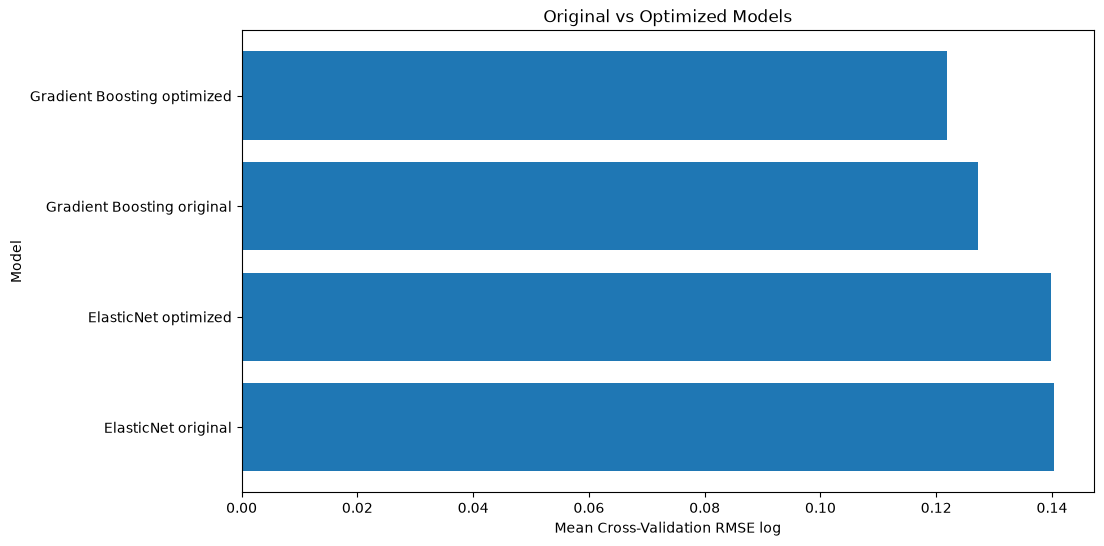

In [50]:
plt.figure(figsize=(11, 6))

plt.barh(
    optimization_comparison["Model"],
    optimization_comparison["CV_RMSE"]
)

plt.xlabel("Mean Cross-Validation RMSE log")
plt.ylabel("Model")
plt.title("Original vs Optimized Models")

plt.gca().invert_yaxis()

plt.show()

In [51]:
if gbr_best_rmse <= elasticnet_best_rmse:

    best_model_name = (
        "Optimized Gradient Boosting"
    )

    best_model = (
        gradient_boosting_random_search
        .best_estimator_
    )

    best_cv_rmse = gbr_best_rmse

else:

    best_model_name = (
        "Optimized ElasticNet"
    )

    best_model = (
        elasticnet_grid_search
        .best_estimator_
    )

    best_cv_rmse = elasticnet_best_rmse

In [52]:
print("Modelo final seleccionado:", best_model_name)
print(f"Mejor CV RMSE: {best_cv_rmse:.5f}")

Modelo final seleccionado: Optimized Gradient Boosting
Mejor CV RMSE: 0.12191


In [53]:
final_scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
    "R2": "r2"
}

In [54]:
final_cv_results = cross_validate(
    estimator=best_model,
    X=X,
    y=y,
    cv=cv,
    scoring=final_scoring,
    n_jobs=-1,
    return_train_score=True
)

In [55]:
final_train_rmse = -(
    final_cv_results["train_RMSE"]
)

final_validation_rmse = -(
    final_cv_results["test_RMSE"]
)

final_validation_mae = -(
    final_cv_results["test_MAE"]
)

final_validation_r2 = (
    final_cv_results["test_R2"]
)

In [60]:
print("Modelo:", best_model_name)

print(
    f"Train RMSE medio: "
    f"{final_train_rmse.mean():.5f}"
)

print(
    f"CV RMSE medio: "
    f"{final_validation_rmse.mean():.5f}"
)

print(
    f"CV RMSE desviación: "
    f"{final_validation_rmse.std():.5f}"
)

print(
    f"CV MAE medio: "
    f"{final_validation_mae.mean():.5f}"
)

print(
    f"CV R² medio: "
    f"{final_validation_r2.mean():.5f}"
)

print(
    f"Overfitting gap: "
    f"{(final_validation_rmse.mean()- final_train_rmse.mean()):.5f}"
)

Modelo: Optimized Gradient Boosting
Train RMSE medio: 0.08280
CV RMSE medio: 0.12191
CV RMSE desviación: 0.01490
CV MAE medio: 0.08325
CV R² medio: 0.90222
Overfitting gap: 0.03911


In [61]:
best_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](87,)","['Id','MSSubClass','MSZoning',...,'HasGarage','HasBasement','HasFireplace']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,87
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This s

In [62]:
test_predictions_log = best_model.predict(
    X_test
)

In [63]:
test_predictions = np.expm1(
    test_predictions_log
)

In [64]:
print(
    "Número de predicciones:",
    len(test_predictions)
)

print(
    "Precio mínimo predicho:",
    test_predictions.min()
)

print(
    "Precio máximo predicho:",
    test_predictions.max()
)

print(
    "Predicciones negativas:",
    (test_predictions < 0).sum()
)

print(
    "Predicciones NaN:",
    np.isnan(test_predictions).sum()
)

Número de predicciones: 292
Precio mínimo predicho: 51850.892910589326
Precio máximo predicho: 519863.21149873827
Predicciones negativas: 0
Predicciones NaN: 0


In [65]:
submission = pd.DataFrame({
    "Id": test["Id"],
    "SalePrice": test_predictions
})

In [66]:
submission.head(10)

,Id,SalePrice
0,893,142541.046392
1,1106,352977.751730
2,414,108139.268309
3,523,151310.777630
4,1037,317402.799723
5,615,76397.236657
6,219,223907.460902
7,1161,144569.507087
8,650,74427.571724
9,888,134753.076181


In [67]:
print("Submission shape:", submission.shape)

print(
    "Missing values:"
)

print(
    submission.isna().sum()
)

Submission shape: (292, 2)
Missing values:
Id           0
SalePrice    0
dtype: int64


In [68]:
sample_submission_path = (
    DATA_PATH / "sample_submission.csv"
)

In [69]:
if sample_submission_path.exists():

    sample_submission = pd.read_csv(
        sample_submission_path
    )

    print(
        "Mismas columnas:",
        submission.columns.tolist()
        == sample_submission.columns.tolist()
    )

    print(
        "Mismo número de filas:",
        len(submission)
        == len(sample_submission)
    )

else:

    print(
        "No se encontró sample_submission.csv"
    )

Mismas columnas: True
Mismo número de filas: True


In [70]:
submission_path = (
    SUBMISSIONS_PATH
    / "submission_optimized.csv"
)

submission.to_csv(
    submission_path,
    index=False
)

print(
    "Submission guardada en:",
    submission_path
)

Submission guardada en: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\submissions\submission_optimized.csv


In [72]:
import joblib

In [73]:
model_path = (
    MODELS_PATH
    / "best_model.joblib"
)

joblib.dump(
    best_model,
    model_path
)

print(
    "Modelo guardado en:",
    model_path
)

Modelo guardado en: c:\Users\r.carrillo\OneDrive - MultiSafepay\Desktop\kaggle house price\models\best_model.joblib


## Conclusions

The model comparison performed in the previous notebook identified
Gradient Boosting as the best initial model, with a mean cross-validation
log-RMSE of 0.12729. ElasticNet was the best regularized linear model,
with a mean log-RMSE of 0.14026.

Both models were optimized using the same five cross-validation folds.

ElasticNet was optimized using GridSearchCV, testing different values
of `alpha` and `l1_ratio`.

Gradient Boosting was optimized using RandomizedSearchCV. The search
included the number of estimators, learning rate, maximum tree depth,
minimum samples required to split a node, minimum samples per leaf,
subsampling, and the number of features considered by each tree.

The final model was selected based on the lowest mean cross-validation
log-RMSE. Training performance and validation performance were also
compared to monitor overfitting.

The selected model was trained on the complete training dataset and
used to predict the prices of the Kaggle test observations. Predictions
were transformed back to the original price scale using `np.expm1()`
and saved as `submission_optimized.csv`.